# Занятие 5. Сравнение моделей и выбор решения

В заказе, принятом сегодня, мы ещё не знаем, опоздает ли доставка. Зато уже знаем город, тип доставки, обещанный срок, текущую загрузку склада и несколько других признаков. На этих сведениях можно оценить риск, а затем решить, какие заявки передать команде сопровождения. Вероятность и действие здесь разные сущности: даже хорошая оценка риска сама по себе никого не предупреждает и не меняет маршрут.

Мы сравним три уже знакомых алгоритма на одних и тех же будущих относительно обучения заказах. Отдельно посмотрим, насколько их вероятности соответствуют наблюдаемым частотам, и зафиксируем правило действия при условных стоимостях ошибок и ограниченном числе заявок, которые команда успевает обработать. Только после фиксации решения откроем отложенный период. Все примеры используют синтетические учебные данные; денежные числа ниже выражены в условных единицах и не являются оценкой реального эффекта вмешательства.

Сохранённые результаты ячеек позволяют читать занятие как выполненный эксперимент. Код оставлен воспроизводимым: относительный путь к CSV и папке outputs рассчитан на запуск из каталога этого модуля. По ходу занятия полезно возвращаться к трём вопросам. Какие сведения доступны именно в момент оформления? На каком периоде принято очередное решение? Какую рабочую величину выражает показанная метрика? Если ответ на один из них меняется, сравнение уже описывает другую задачу. Поэтому таблицы, графики и упражнения выстроены в порядке, который фиксирует каждое решение до просмотра следующего периода. Сохранённые выводы служат материалом для разбора, а код позволяет воспроизвести расчёт в той же среде.

## 1. Временной эксперимент и одинаковые строки

До сравнения алгоритмов определим момент прогноза и доступные сведения. Столбцы с фактической задержкой и компенсацией появляются после доставки и не могут участвовать в прогнозе. Идентификаторы и служебные временные метки нужны для проверки набора, но не входят в матрицу признаков. Мы заранее закрепляем календарные границы, чтобы одинаковые строки попадали в обучение и проверку каждого кандидата.

**Импорты и константы**

Задаём единственный список разрешённых признаков и календарные границы в одном месте. Все импорты этого ноутбука находятся в первой исполняемой ячейке. Это удобно для проверки: последующие шаги используют уже определённые имена и не скрывают внешние зависимости.

In [1]:
# Шаг М2.05.01 — Импорты и константы
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (average_precision_score, brier_score_loss, precision_score,
                             recall_score, confusion_matrix, precision_recall_curve)
from sklearn.calibration import calibration_curve

NUMERIC = ['distance_km', 'items_count', 'order_amount', 'warehouse_load',
           'customer_prior_orders', 'promised_days', 'order_hour']
CATEGORICAL = ['city', 'product_category', 'delivery_type',
               'weather_forecast', 'is_weekend']
FEATURES = NUMERIC + CATEGORICAL
TRAIN_END = pd.Timestamp('2026-07-25')
VALID_START, VALID_END = pd.Timestamp('2026-08-01'), pd.Timestamp('2026-09-24')
TEST_START = pd.Timestamp('2026-10-01')
OUT = Path('outputs/05')
OUT.mkdir(parents=True, exist_ok=True)
print('Число признаков:', len(FEATURES))

Число признаков: 12


**Чтение учебного снимка**

Открываем один CSV, созданный для сценария задержек. Это синтетический снимок заказов за 2026 год. Цель `late_delivery` равна единице, когда доставка опоздала. В таблице есть сведения, которые мы позже исключим из признаков.

In [2]:
# Шаг М2.05.02 — Чтение учебного снимка
data = pd.read_csv('data/delivery_risk.csv', parse_dates=['order_ts', 'label_available_at'])
print('Строк и столбцов:', data.shape)
print('Доля задержек:', round(data['late_delivery'].mean(), 4))
print('Временной диапазон:', data['order_ts'].min(), '—', data['order_ts'].max())

Строк и столбцов: (14000, 19)
Доля задержек: 0.1261
Временной диапазон: 2026-01-01 00:00:00 — 2026-12-31 23:59:00


**Проверка доступности признаков**

Проверяем, что каждый ожидаемый столбец есть в CSV, а постфактум поля исключены. Такая проверка страхует занятие от случайной смены схемы данных. Использование только `FEATURES` далее делает исключение утечек наблюдаемым в коде.

In [3]:
# Шаг М2.05.03 — Проверка доступности признаков
required = set(FEATURES + ['order_ts', 'label_available_at', 'late_delivery'])
assert required.issubset(data.columns)
assert not {'actual_delay_hours', 'compensation_paid', 'customer_id',
            'request_id', 'order_ts', 'label_available_at'} & set(FEATURES)
print('Разрешённые числовые:', NUMERIC)
print('Разрешённые категориальные:', CATEGORICAL)

Разрешённые числовые: ['distance_km', 'items_count', 'order_amount', 'warehouse_load', 'customer_prior_orders', 'promised_days', 'order_hour']
Разрешённые категориальные: ['city', 'product_category', 'delivery_type', 'weather_forecast', 'is_weekend']


**Календарные маски**

Обучаем на заказах до 25 июля, проверяем кандидатов на заказах с 1 августа до 24 сентября. Между ними оставляем семь дней. Второй промежуток с 24 сентября до 1 октября отделяет проверку от будущей итоговой оценки. Пока создаём только train и validation; отложенный период не читаем.

In [4]:
# Шаг М2.05.04 — Календарные маски
train_mask = data['order_ts'] < TRAIN_END
valid_mask = (data['order_ts'] >= VALID_START) & (data['order_ts'] < VALID_END)
train = data.loc[train_mask].copy()
valid = data.loc[valid_mask].copy()
assert train['order_ts'].max() < VALID_START
assert valid['order_ts'].max() < TEST_START
print('Обучение:', len(train), 'Проверка:', len(valid))

Обучение: 7863 Проверка: 2072


**Зрелость меток**

Метка становится доступной через семь дней после заказа. Проверяем, что обучающие метки созрели до начала validation, а проверочные — до начала test. Это защищает сценарий от использования исхода, который на дату решения ещё не мог быть известен.

In [5]:
# Шаг М2.05.05 — Зрелость меток
assert (train['label_available_at'] <= VALID_START).all()
assert (valid['label_available_at'] <= TEST_START).all()
assert data['label_available_at'].max() <= pd.Timestamp('2027-01-08')
print('Последняя метка обучения:', train['label_available_at'].max())
print('Последняя метка проверки:', valid['label_available_at'].max())

Последняя метка обучения: 2026-07-31 23:42:27
Последняя метка проверки: 2026-09-30 23:58:51


**Единые матрицы для кандидатов**

Выделяем признаки и цель ровно один раз. Каждый кандидат увидит одинаковые обучающие строки и будет оценён на одинаковых validation строках. Базовая частота цели в двух периодах помогает заметить временной сдвиг до выбора модели.

In [6]:
# Шаг М2.05.06 — Единые матрицы для кандидатов
X_train, y_train = train[FEATURES], train['late_delivery'].astype(int)
X_valid, y_valid = valid[FEATURES], valid['late_delivery'].astype(int)
print(pd.DataFrame({'период': ['train', 'validation'],
                    'заказов': [len(train), len(valid)],
                    'доля_задержек': [y_train.mean(), y_valid.mean()]}).to_string(index=False))
print('Пропуски по признакам в validation:', int(X_valid.isna().sum().sum()))

    период  заказов  доля_задержек
     train     7863       0.118148
validation     2072       0.115347
Пропуски по признакам в validation: 175


Мы зафиксировали момент прогноза, разрешённые признаки и временные границы. Промежутки обеспечивают зрелость меток. Теперь различия в результатах кандидатов можно связывать с моделями, а не со случайно выбранными для них строками.

## 2. Сравнение кандидатов на validation

Метрики Accuracy, Precision, Recall, F1, ROC-AUC и AP уже использовались в предыдущих занятиях. Здесь выбираем модель по AP на validation: событие редкое, а нам важно качество ранжирования положительных заказов. Частотный Dummy служит ориентиром. Итоговое правило действия пока не определяется.

**Обработка признаков внутри конвейера**

Числовые пропуски заменяем медианой и добавляем признаки пропуска. Масштабирование используем только для логистической регрессии. Категории заполняем наиболее частым значением, а неизвестные уровни кодируем без аварии. Все статистики обработки будут изучены только на train.

In [7]:
# Шаг М2.05.07 — Обработка признаков внутри конвейера
def make_prepare(scale_numeric):
    numeric_steps = [('impute', SimpleImputer(strategy='median', add_indicator=True))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), NUMERIC),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), CATEGORICAL)
    ])

print('Подготовка создаётся внутри каждого кандидата')

Подготовка создаётся внутри каждого кандидата


**Четыре фиксированных кандидата**

Создаём три содержательных модели с заранее заданными параметрами и частотный базовый вариант. Случайность фиксирована там, где она влияет на обучение. Лес работает в два потока; в учебной среде это ограничивает нагрузку.

In [8]:
# Шаг М2.05.08 — Четыре фиксированных кандидата
models = {
    'logistic': Pipeline([('prepare', make_prepare(True)),
                          ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))]),
    'tree': Pipeline([('prepare', make_prepare(False)),
                      ('model', DecisionTreeClassifier(max_depth=5, min_samples_leaf=50,
                                                       random_state=42))]),
    'forest': Pipeline([('prepare', make_prepare(False)),
                        ('model', RandomForestClassifier(n_estimators=120, max_depth=9,
                                                         min_samples_leaf=15, max_features=0.7,
                                                         n_jobs=2, random_state=42))]),
    'dummy': DummyClassifier(strategy='prior')
}
print(list(models))

['logistic', 'tree', 'forest', 'dummy']


**Обучение без будущих строк**

Обучаем все четыре варианта только на `X_train` и `y_train`. Проверочный набор будет использоваться лишь для сравнения. Для каждого кандидата сохраняем положительную вероятность на тех же строках validation.

In [9]:
# Шаг М2.05.09 — Обучение без будущих строк
valid_prob = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    valid_prob[name] = model.predict_proba(X_valid)[:, 1]
    print(name, 'обучена, прогнозов:', len(valid_prob[name]))
assert len({len(p) for p in valid_prob.values()}) == 1

logistic обучена, прогнозов: 2072
tree обучена, прогнозов: 2072


forest обучена, прогнозов: 2072
dummy обучена, прогнозов: 2072


**Таблица ранжирования**

Считаем AP для каждой модели и показываем базовую частоту события. Сортировка по AP — заранее выбранное правило выбора алгоритма. Значения на test здесь отсутствуют.

In [10]:
# Шаг М2.05.10 — Таблица ранжирования
comparison = pd.DataFrame([
    {'модель': name, 'AP_validation': average_precision_score(y_valid, prob),
     'средний_риск': float(np.mean(prob))}
    for name, prob in valid_prob.items()
]).sort_values(['AP_validation', 'модель'], ascending=[False, True]).reset_index(drop=True)
display(comparison)
print('Частота события validation:', round(y_valid.mean(), 4))

,модель,AP_validation,средний_риск
0,forest,0.321099,0.121847
1,logistic,0.312494,0.123186
2,tree,0.296406,0.121078
3,dummy,0.115347,0.118148


Частота события validation: 0.1153


**Одна шкала precision–recall**

Строим кривые по validation, чтобы увидеть, при какой доле найденных задержек теряется точность предупреждений. Ступенчатые кривые показывают возможные пороги, а горизонтальная линия — частотный ориентир Dummy. Конкретный порог будет выбран по затратам и мощности команды позже.

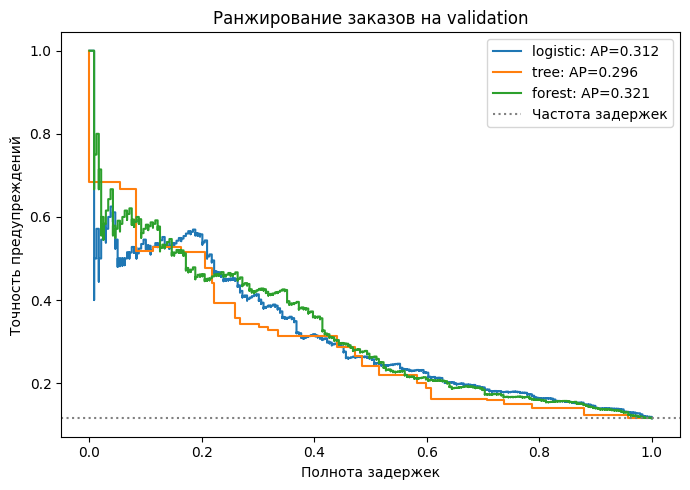

In [11]:
# Шаг М2.05.11 — Одна шкала precision–recall
fig, ax = plt.subplots(figsize=(7, 5))
for name in ['logistic', 'tree', 'forest']:
    precision, recall, _ = precision_recall_curve(y_valid, valid_prob[name])
    ax.step(recall, precision, where='post', label=f'{name}: AP={average_precision_score(y_valid, valid_prob[name]):.3f}')
ax.axhline(y_valid.mean(), color='gray', linestyle=':', label='Частота задержек')
ax.set(xlabel='Полнота задержек', ylabel='Точность предупреждений',
       title='Ранжирование заказов на validation')
ax.legend()
fig.tight_layout()
plt.show()

**Выбор лидера и сравнение с базовой линией**

Убедимся, что выбранный по AP алгоритм лучше частотной заглушки на том же validation. Выводим разницу без объявления статистической значимости: одно временное окно не даёт универсальной гарантии.

In [12]:
# Шаг М2.05.12 — Выбор лидера и сравнение с базовой линией
winner_name = comparison.iloc[0]['модель']
winner_prob = valid_prob[winner_name]
ap_gain = average_precision_score(y_valid, winner_prob) - average_precision_score(y_valid, valid_prob['dummy'])
print('Лидер:', winner_name, 'Прирост AP над Dummy:', round(ap_gain, 4))
assert winner_name != 'dummy' and ap_gain > 0

Лидер: forest Прирост AP над Dummy: 0.2058


Модель выбрана по AP на одних и тех же validation строках. Мы пока знаем качество ранжирования, но ещё не знаем, какие заявки передавать команде. Следующий раздел проверит смысл вероятностей и задаст ограниченное действие.

## 3. Вероятность, стоимость и мощность команды

Хорошее ранжирование не означает, что прогноз 0,30 соответствует примерно 30% задержек. Калибровочная диаграмма группирует validation прогнозы и сравнивает средний риск с долей событий. Brier — средний квадрат разности между вероятностью и двоичной меткой: меньше лучше. Здесь мы только диагностируем калибровку, не обучаем дополнительный калибратор. Затем на validation выбираем порог при условных ценах ошибок без учёта мощности команды. После выбора добавляем предел обработки десять процентов пакета. Это последовательное правило, а не совместный оптимум порога и лимита.

**Определение и расчёт Brier**

Для каждой строки квадрат ошибки равен `(p - y)²`, где `p` — прогнозная вероятность, `y` — ноль или один. Среднее этих квадратов даёт Brier. Вычислим его для всех кандидатов на validation рядом со средним риском.

In [13]:
# Шаг М2.05.13 — Определение и расчёт Brier
brier_table = pd.DataFrame([
    {'модель': name, 'Brier_validation': brier_score_loss(y_valid, prob),
     'средний_риск': np.mean(prob), 'фактическая_частота': y_valid.mean()}
    for name, prob in valid_prob.items()
]).sort_values('Brier_validation')
display(brier_table)

,модель,Brier_validation,средний_риск,фактическая_частота
2,forest,0.091798,0.121847,0.115347
0,logistic,0.092133,0.123186,0.115347
1,tree,0.093117,0.121078,0.115347
3,dummy,0.102050,0.118148,0.115347


**Калибровочная диаграмма**

Разбиваем прогнозы лидера и Dummy на группы по предсказанной вероятности. По горизонтали показываем среднее предсказание, по вертикали фактическую долю задержек. Точки у диагонали согласуются с частотной интерпретацией; малые корзины трактуем осторожно.

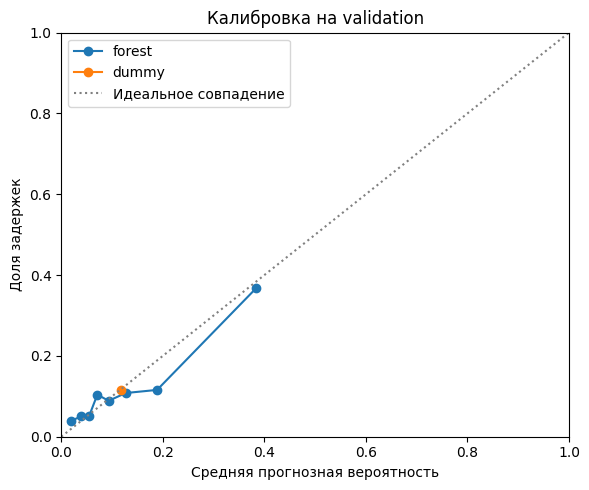

In [14]:
# Шаг М2.05.14 — Калибровочная диаграмма
fig, ax = plt.subplots(figsize=(6, 5))
for name in [winner_name, 'dummy']:
    observed, predicted = calibration_curve(y_valid, valid_prob[name], n_bins=8, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=name)
ax.plot([0, 1], [0, 1], linestyle=':', color='gray', label='Идеальное совпадение')
ax.set(xlabel='Средняя прогнозная вероятность', ylabel='Доля задержек',
       title='Калибровка на validation', xlim=(0, 1), ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()

**Сценарий стоимости ошибок**

Задаём учебные цены: пропущенная задержка стоит пять условных единиц, лишнее предупреждение — одну. Это условная функция потерь для выбора порога без ограничения мощности, а не бухгалтерская оценка. В исторических данных нет результата вмешательства, поэтому расчёт не доказывает, что предупреждение устранит задержку.

In [15]:
# Шаг М2.05.15 — Сценарий стоимости ошибок
COST_FN, COST_FP = 5, 1
threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
print('Цена пропуска:', COST_FN, 'Цена лишнего предупреждения:', COST_FP)
print('Порогов в сетке:', len(threshold_grid))

Цена пропуска: 5 Цена лишнего предупреждения: 1
Порогов в сетке: 91


**Поиск порога на validation**

Для каждого заранее заданного порога считаем ложные срабатывания, пропуски, условные потери и долю предупреждений. При равной стоимости выбираем более высокий порог: он меньше загружает команду. Данные test в этом поиске не участвуют. Лимит мощности добавляется позже, поэтому выбранный порог не объявляется оптимальным для совместного правила. Лимит мощности добавляется позже, поэтому выбранный порог не объявляется оптимальным для совместного правила. Лимит мощности добавляется позже, поэтому выбранный порог не объявляется оптимальным для совместного правила. Лимит мощности добавляется позже, поэтому выбранный порог не объявляется оптимальным для совместного правила.

In [16]:
# Шаг М2.05.16 — Поиск порога на validation
rows = []
for threshold in threshold_grid:
    alert = winner_prob >= threshold
    fp = int(((y_valid == 0) & alert).sum())
    fn = int(((y_valid == 1) & ~alert).sum())
    rows.append({'порог': float(threshold), 'FP': fp, 'FN': fn,
                 'стоимость': COST_FP * fp + COST_FN * fn,
                 'доля_сигналов': float(alert.mean())})
threshold_table = pd.DataFrame(rows)
best_row = threshold_table.sort_values(['стоимость', 'порог'], ascending=[True, False]).iloc[0]
threshold = float(best_row['порог'])
display(best_row.to_frame().T)

,порог,FP,FN,стоимость,доля_сигналов
18,0.23,183.0,140.0,883.0,0.1361


**Цена и нагрузка по порогам**

График показывает компромисс между условными потерями и числом заявок. Минимум стоимости может требовать больше обработок, чем команда способна выполнить. Поэтому одно только оптимальное значение функции потерь не завершает решение.

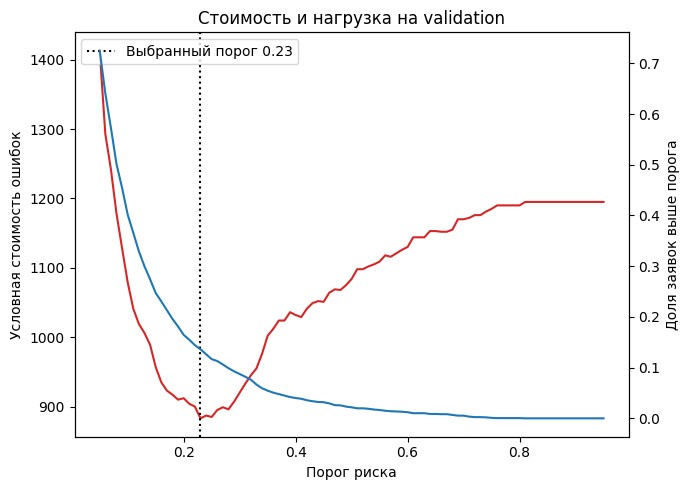

In [17]:
# Шаг М2.05.17 — Цена и нагрузка по порогам
fig, left = plt.subplots(figsize=(7, 5))
left.plot(threshold_table['порог'], threshold_table['стоимость'], color='tab:red')
left.axvline(threshold, linestyle=':', color='black', label=f'Выбранный порог {threshold:.2f}')
left.set(xlabel='Порог риска', ylabel='Условная стоимость ошибок',
         title='Стоимость и нагрузка на validation')
right = left.twinx()
right.plot(threshold_table['порог'], threshold_table['доля_сигналов'], color='tab:blue')
right.set_ylabel('Доля заявок выше порога')
left.legend(loc='upper left')
fig.tight_layout()
plt.show()

**Конечная мощность: верхние 10%**

Команда может обработать не более 10% заказов пакета. Среди строк с риском выше порога берём самые рискованные, остальные не отмечаем. Равные риски разрешаем исходным порядком строк, чтобы результат был воспроизводимым. Такое ограничение применяется одинаково к validation и будущему пакету.

In [18]:
# Шаг М2.05.18 — Конечная мощность: верхние 10%
CAPACITY_SHARE = 0.10
def apply_policy(probabilities, threshold, capacity_share):
    probabilities = np.asarray(probabilities, dtype=float)
    limit = int(np.floor(len(probabilities) * capacity_share))
    alert = np.zeros(len(probabilities), dtype=bool)
    order = np.argsort(-probabilities, kind='stable')
    chosen = order[probabilities[order] >= threshold][:limit]
    alert[chosen] = True
    return alert

valid_alert = apply_policy(winner_prob, threshold, CAPACITY_SHARE)
print('Мощность:', int(np.floor(len(valid) * CAPACITY_SHARE)))
print('Отмечено:', int(valid_alert.sum()), 'Доля:', round(valid_alert.mean(), 4))

Мощность: 207
Отмечено: 207 Доля: 0.0999


**Операционные метрики политики**

Считаем качество уже применённого правила: сколько отмеченных заказов действительно задержалось, какую долю задержек нашли и сколько стоят ошибки в условных единицах. Эти значения относятся к validation, где правило выбрано, и не заменяют итоговую оценку.

In [19]:
# Шаг М2.05.19 — Операционные метрики политики
valid_fp = int(((y_valid == 0) & valid_alert).sum())
valid_fn = int(((y_valid == 1) & ~valid_alert).sum())
valid_policy = {
    'precision': precision_score(y_valid, valid_alert, zero_division=0),
    'recall': recall_score(y_valid, valid_alert, zero_division=0),
    'FP': valid_fp, 'FN': valid_fn,
    'условная_стоимость': COST_FP * valid_fp + COST_FN * valid_fn,
    'доля_обработки': float(valid_alert.mean())
}
display(pd.Series(valid_policy, name='validation'))

precision               0.405797
recall                  0.351464
FP                    123.000000
FN                    155.000000
условная_стоимость    898.000000
доля_обработки          0.099903
Name: validation, dtype: float64

**Подгруппы на validation**

Сравниваем города только при достаточном числе строк и задержек. Малые подгруппы дают шумные доли, поэтому задаём минимумы 100 заказов и 10 задержек. Пустая таблица была бы сигналом пересмотреть размер групп, а не поводом интерпретировать единичные случаи.

In [20]:
# Шаг М2.05.20 — Подгруппы на validation
valid_view = valid[['city', 'late_delivery']].copy()
valid_view['сигнал'] = valid_alert
group_rows = []
for city, part in valid_view.groupby('city', dropna=False):
    positives = int(part['late_delivery'].sum())
    if len(part) < 100 or positives < 10:
        continue
    group_rows.append({'город': str(city), 'заказов': len(part), 'задержек': positives,
                       'доля_сигналов': part['сигнал'].mean(),
                       'полнота': recall_score(part['late_delivery'], part['сигнал'], zero_division=0)})
valid_groups = pd.DataFrame(group_rows).sort_values('заказов', ascending=False)
display(valid_groups)

,город,заказов,задержек,доля_сигналов,полнота
2,Москва,635,67,0.089764,0.328358
3,Санкт-Петербург,280,35,0.114286,0.457143
0,Екатеринбург,116,16,0.155172,0.500000
1,Казань,105,13,0.114286,0.153846


На validation выбран алгоритм по AP, проверена калибровка, задан порог условных потерь и добавлен предел мощности. Различие между вероятностью и действием теперь видно в коде: одна и та же вероятность может не привести к сигналу, если пакет уже заполнен более рискованными заявками.

## 4. Зафиксированное решение и однократная проверка

Перед чтением test сохраняем имя модели, признаки, границы периодов, порог, ограничение мощности и цены ошибок в JSON. Это зафиксированная версия учебного решения. Затем выполняем одну итоговую оценку на октябрьских и последующих заказах. После просмотра результата ничего не перенастраиваем.

**Запись политики до test**

Сохраняем выбранное решение и правила оценки в `outputs/05/decision.json`. JSON — текстовый формат объектов и массивов, читаемый человеком и программой. JSON — текстовый формат объектов и массивов, читаемый человеком и программой. JSON — текстовый формат объектов и массивов, читаемый человеком и программой. JSON — текстовый формат объектов и массивов, читаемый человеком и программой. Файл создаётся до первого обращения к отложенным строкам. Он помогает сверить последующую итоговую оценку с исходным выбором.

In [21]:
# Шаг М2.05.21 — Запись политики до test
decision = {
    'model': winner_name, 'features': FEATURES,
    'train_end_exclusive': str(TRAIN_END.date()),
    'validation_start': str(VALID_START.date()),
    'validation_end_exclusive': str(VALID_END.date()),
    'test_start': str(TEST_START.date()),
    'selection_metric': 'average_precision_validation',
    'threshold': threshold, 'capacity_share': CAPACITY_SHARE,
    'cost_false_negative': COST_FN, 'cost_false_positive': COST_FP,
    'validation_ap': float(average_precision_score(y_valid, winner_prob))
}
(OUT / 'decision.json').write_text(json.dumps(decision, ensure_ascii=False, indent=2), encoding='utf-8')
print('Решение сохранено:', OUT / 'decision.json')
print('Модель:', decision['model'], 'Порог:', decision['threshold'])

Решение сохранено: outputs\05\decision.json
Модель: forest Порог: 0.23


**Первое открытие отложенного периода**

Теперь, после записи решения, выделяем заказы с 1 октября. Проверяем, что их метки успели появиться к дате учебного снимка. Признаки извлекаем тем же фиксированным списком; новое обучение не происходит.

In [22]:
# Шаг М2.05.22 — Первое открытие отложенного периода
test = data.loc[data['order_ts'] >= TEST_START].copy()
assert (test['label_available_at'] <= pd.Timestamp('2027-01-08')).all()
X_test, y_test = test[FEATURES], test['late_delivery'].astype(int)
test_prob = models[winner_name].predict_proba(X_test)[:, 1]
test_alert = apply_policy(test_prob, threshold, CAPACITY_SHARE)
print('Отложенных заказов:', len(test), 'Отмечено:', int(test_alert.sum()))

Отложенных заказов:

 3529 Отмечено: 352


**Итоговая оценка test**

Одним блоком вычисляем AP, Brier и метрики зафиксированного действия. Числа FP и FN позволяют проверить условную стоимость. Это финальная оценка, после которой модель и порог остаются прежними.

In [23]:
# Шаг М2.05.23 — Итоговая оценка test
test_fp = int(((y_test == 0) & test_alert).sum())
test_fn = int(((y_test == 1) & ~test_alert).sum())
test_result = {
    'заказов': len(test), 'частота_задержек': float(y_test.mean()),
    'AP': float(average_precision_score(y_test, test_prob)),
    'Brier': float(brier_score_loss(y_test, test_prob)),
    'precision_сигналов': float(precision_score(y_test, test_alert, zero_division=0)),
    'recall_задержек': float(recall_score(y_test, test_alert, zero_division=0)),
    'доля_обработки': float(test_alert.mean()),
    'FP': test_fp, 'FN': test_fn,
    'условная_стоимость': COST_FP * test_fp + COST_FN * test_fn
}
display(pd.Series(test_result, name='test'))
print('Матрица ошибок [0, 1]:\n', confusion_matrix(y_test, test_alert))

заказов               3529.000000
частота_задержек         0.151034
AP                       0.393344
Brier                    0.112584
precision_сигналов       0.474432
recall_задержек          0.313321
доля_обработки           0.099745
FP                     185.000000
FN                     366.000000
условная_стоимость    2015.000000
Name: test, dtype: float64

Матрица ошибок [0, 1]:
 [[2811  185]
 [ 366  167]]


**Честные виды ошибок**

Посмотрим на количество правильных и ошибочных решений и несколько заявок с высоким риском без персональных идентификаторов. Это описание уже выполненной оценки, а не новый поиск порога. Постфактум поля не выводим как признаки.

In [24]:
# Шаг М2.05.24 — Честные виды ошибок
error_counts = pd.Series({
    'верно_не_отмечено': int(((y_test == 0) & ~test_alert).sum()),
    'лишний_сигнал': test_fp,
    'пропущенная_задержка': test_fn,
    'верно_отмечено': int(((y_test == 1) & test_alert).sum())
})
display(error_counts)
examples = test[['order_ts', 'city', 'delivery_type', 'late_delivery']].copy()
examples['риск'] = test_prob
examples['сигнал'] = test_alert
display(examples.sort_values('риск', ascending=False).head(5))

верно_не_отмечено       2811
лишний_сигнал            185
пропущенная_задержка     366
верно_отмечено           167
dtype: int64

,order_ts,city,delivery_type,late_delivery,риск,сигнал
12950,2026-12-04 15:33:48,Москва,Экспресс,1,0.788385,True
11898,2026-11-07 05:15:58,Москва,Экспресс,0,0.780252,True
11868,2026-11-06 10:29:36,Екатеринбург,Экспресс,0,0.767903,True
11599,2026-10-30 10:09:52,Волгоград,Экспресс,1,0.760479,True
11188,2026-10-19 16:58:41,Уфа,Экспресс,1,0.751441,True


**Новый город как диагностическая подгруппа**

Проверяем отложенную подгруппу «Новый город», которой не было в train. Показываем размер и число задержек, а метрики выводим только при минимуме 100 строк и 10 событий. Отсутствие категории в обучающем словаре не означает доказанной устойчивости качества.

In [25]:
# Шаг М2.05.25 — Новый город как диагностическая подгруппа
known_cities = set(X_train['city'].dropna())
new_city = test['city'].eq('Новый город')
print('Новый город был в train:', 'Новый город' in known_cities)
print('Число заказов / задержек:', int(new_city.sum()), int(y_test[new_city].sum()))
if new_city.sum() >= 100 and y_test[new_city].sum() >= 10:
    print('AP:', round(average_precision_score(y_test[new_city], test_prob[new_city]), 3))
    print('Recall:', round(recall_score(y_test[new_city], test_alert[new_city], zero_division=0), 3))
else:
    print('Подгруппа слишком мала для отдельной интерпретации')

Новый город был в train: False
Число заказов / задержек: 80 15
Подгруппа слишком мала для отдельной интерпретации


Решение было записано до доступа к test, затем оценено один раз. Ошибки представлены количествами, а новый город отмечен как зона наблюдения. Отложенные результаты используются для вывода о проверке, но не для изменения модели или порога.

## 5. Неопределённость и практический вывод

Точечные метрики зависят от конкретных недель. Чтобы показать их изменчивость, используем простую перепроверку с семидневными блоками отложенного периода: случайно выбираем целые недели с возвращением и пересчитываем AP и recall зафиксированных сигналов. Интервал условен на выбранной модели и уже назначенных сигналах: он не включает повторный выбор или обучение модели и влияние формирования новой очереди. Он описывает вариацию наблюдавшихся недель, но не гарантирует качество при новом сезонном сдвиге.

**Семидневные блоки**

Назначаем каждому тестовому заказу номер семидневного блока от начала октября. Внутри блока строки остаются вместе при повторной выборке. Выводим размеры блоков, чтобы понять фактическую единицу перепроверки.

In [26]:
# Шаг М2.05.26 — Семидневные блоки
block_id = ((test['order_ts'].dt.normalize() - TEST_START).dt.days // 7).to_numpy()
blocks = [np.flatnonzero(block_id == value) for value in np.unique(block_id)]
print('Блоков:', len(blocks), 'Размеры:', [len(block) for block in blocks])

Блоков: 14 Размеры: [268, 269, 268, 269, 268, 269, 268, 269, 268, 269, 268, 269, 268, 39]


**Интервалы для AP и полноты**

Двести раз выбираем набор недель с возвращением и пересчитываем AP и recall. Для интервала берём 2,5-й и 97,5-й процентили. Сигналы остаются теми, которые дала зафиксированная политика на исходном тестовом пакете. Очередь и порог в повторных выборках не пересчитываются. Очередь и порог в повторных выборках не пересчитываются. Очередь и порог в повторных выборках не пересчитываются. Очередь и порог в повторных выборках не пересчитываются.

In [27]:
# Шаг М2.05.27 — Интервалы для AP и полноты
rng = np.random.default_rng(42)
replicates = []
for _ in range(200):
    picked = rng.integers(0, len(blocks), size=len(blocks))
    idx = np.concatenate([blocks[i] for i in picked])
    labels = y_test.to_numpy()[idx]
    if labels.min() == labels.max():
        continue
    replicates.append((average_precision_score(labels, test_prob[idx]),
                       recall_score(labels, test_alert[idx], zero_division=0)))
interval = np.percentile(np.asarray(replicates), [2.5, 97.5], axis=0)
print('AP:', round(test_result['AP'], 3), 'интервал:', np.round(interval[:, 0], 3))
print('Recall:', round(test_result['recall_задержек'], 3), 'интервал:', np.round(interval[:, 1], 3))

AP: 0.393 интервал: [0.365 0.426]
Recall: 0.313 интервал: [0.28  0.343]


**Задание: сопоставить риск и действие**

Решение задания выполняется кодом: найдём заявки с риском выше порога, которые не получили сигнал из-за лимита. Их число показывает, почему «достаточно рискован» и «передан на обработку» могут расходиться. Вывод не меняет ранее выбранную политику.

In [28]:
# Шаг М2.05.28 — Задание: сопоставить риск и действие
above_threshold = test_prob >= threshold
blocked_by_capacity = above_threshold & ~test_alert
print('Выше порога:', int(above_threshold.sum()))
print('Не вошло из-за лимита:', int(blocked_by_capacity.sum()))
print('У этих заказов задержек:', int(y_test.to_numpy()[blocked_by_capacity].sum()))
assert not np.any(test_alert & ~above_threshold)

Выше порога: 448
Не вошло из-за лимита: 96
У этих заказов задержек: 24


Семидневная перепроверка дала диапазон для двух итоговых метрик, а упражнение показало роль лимита мощности. Эти результаты не используются для донастройки. Следующее занятие превратит выбранный алгоритм и политику в сохраняемый артефакт, который сможет принимать новые заявки без целевого столбца.

## Полученный результат

Мы честно сравнили четыре фиксированных кандидата на одном validation периоде, выбрали модель по AP, изучили её вероятности с помощью калибровочной диаграммы и Brier. Затем задали условную стоимость ошибок, выбрали порог, ограничили обработку десятью процентами пакета и записали решение до test. Однократная итоговая проверка дала метрики ранжирования и конкретного действия, абсолютные виды ошибок и семидневный бутстреп интервал. Практический результат — воспроизводимая процедура решения, а не обещание снизить задержки на наблюдаемое число: эффект вмешательства историческая цель не измеряет.

Для следующего занятия важно сохранить и подготовку признаков, и модель вместе. Также понадобится явная схема входа: новая заявка ещё не имеет `late_delivery`, фактической задержки или компенсации. Политика должна работать именно с такими неполными по исходу данными.

## Документация

[Average precision](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.average_precision_score.html)

[Калибровка вероятностей](https://scikit-learn.org/1.8/modules/calibration.html)

[Brier score](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.brier_score_loss.html)

[ColumnTransformer](https://scikit-learn.org/1.8/modules/generated/sklearn.compose.ColumnTransformer.html)